# 25 · Step 4: a lower stage-1 threshold, and feature arms

**Purpose.** Plan `2026-10-18-classifier-then-rerank`, step 4 (approved 18 Oct 2026). Step 3 left the
learned stage 1 handing only part of the chat's top 10 to stage 2. **4a** lowers the threshold to
the operating point fixed before looking (t = 0.3, a dev-select size budget) and measures the
ceiling and the end-to-end Recall@10 with step 3's L2. **4b** de-duplicates F12 to F9 and tests
one change at a time for both stages.

**Status.** Reporting only: figures are read from `output/rerank/threshold-ceiling.json` and
`output/rerank/feature-arms.json`. The reference for the top-10 task is the chat's latest score
per pair (`chat-1` plus the fresh `chat-2` chats; D61 as amended). Every CI resamples JDs.

In [1]:
import json

import matplotlib.pyplot as plt
import pandas as pd

from candidate_screener import reporting
from candidate_screener.config import OUTPUT

reporting.style(plt)
th = json.load(open(OUTPUT / "rerank" / "threshold-ceiling.json"))
fa = json.load(open(OUTPUT / "rerank" / "feature-arms.json"))
SCOPES = ("generic", "targeted", "total")
fmt = lambda b: f"{b['value']:+.3f} [{b['ci'][0]:+.3f}, {b['ci'][1]:+.3f}]"
val = lambda b: f"{b['value']:.3f} [{b['ci'][0]:.3f}, {b['ci'][1]:.3f}]"

## 1 · 4a: what each stage-1 list hands over, and what L2 makes of it

In [2]:
rows = {}
for name, b in th["arms"].items():
    r = b["summary"]["recall"]
    row = {"list per JD, median [min, max]": "{median:.0f} [{min}, {max}]".format(**b["returned"]),
           "ceiling total": val(b["ceiling"]["total"]) if "ceiling" in b else "",
           "ceiling gen / tar": (f"{b['ceiling']['generic']['value']:.3f} / {b['ceiling']['targeted']['value']:.3f}"
                                 if "ceiling" in b else ""),
           "R@10 total": val(r["total"]), "R@10 gen / tar": f"{r['generic']['value']:.3f} / {r['targeted']['value']:.3f}",
           "No Fits": f"{b['summary']['no_fits']['total']['value']:.2f}"}
    if "delta_vs_x2_alone" in b:
        row["R@10 Δ vs X2 alone"] = fmt(b["delta_vs_x2_alone"]["recall"]["total"])
    rows[name] = row
print("bar:", th["bar"]["arm"], f"{th['bar']['recall_delta']:+.3f}", th["bar"]["ci"], "->", th["bar"]["verdict"])
pd.DataFrame(rows).T

bar: t = 0.3 -> L2 vs X2 alone +0.050 [0.017321, 0.083862] -> fail


,"list per JD, median [min, max]",ceiling total,ceiling gen / tar,R@10 total,R@10 gen / tar,No Fits,R@10 Δ vs X2 alone
X2 alone,"10 [10, 10]",,,"0.417 [0.366, 0.467]",0.419 / 0.414,1.73,NaN
X2 top 100 -> L2,"100 [100, 100]","0.964 [0.933, 0.987]",0.960 / 0.971,"0.482 [0.434, 0.529]",0.488 / 0.470,1.37,"+0.065 [+0.034, +0.099]"
t = 0.5,"23 [1, 81]","0.655 [0.570, 0.735]",0.721 / 0.523,"0.438 [0.384, 0.492]",0.454 / 0.406,0.72,"+0.021 [-0.018, +0.062]"
t = 0.4,"32 [1, 98]","0.748 [0.673, 0.819]",0.794 / 0.657,"0.458 [0.406, 0.508]",0.459 / 0.455,1.08,"+0.041 [+0.007, +0.076]"
t = 0.3,"56 [1, 142]","0.858 [0.797, 0.912]",0.878 / 0.817,"0.467 [0.416, 0.516]",0.468 / 0.465,1.27,"+0.050 [+0.017, +0.084]"
X2 top 100 -> L2 (F9),"100 [100, 100]","0.964 [0.933, 0.987]",0.960 / 0.971,"0.483 [0.438, 0.528]",0.486 / 0.479,1.32,"+0.066 [+0.035, +0.100]"
t = 0.3 (F9),"56 [1, 142]","0.858 [0.797, 0.912]",0.878 / 0.817,"0.465 [0.414, 0.515]",0.466 / 0.464,1.28,"+0.048 [+0.015, +0.082]"


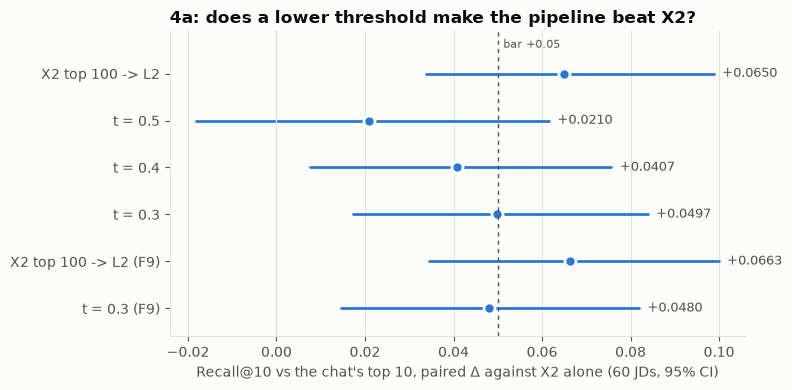

In [3]:
cands = [(n, b["delta_vs_x2_alone"]["recall"]["total"]) for n, b in th["arms"].items() if "delta_vs_x2_alone" in b]
fig, ax = plt.subplots(figsize=(8, 0.5 * len(cands) + 1))
reporting.dot_ci(ax, [n for n, _ in cands], [d["value"] for _, d in cands],
                 [d["ci"][0] for _, d in cands], [d["ci"][1] for _, d in cands], ref=th["bar"]["threshold"], ref_label="bar +0.05", fmt="{:+.4f}")
ax.axvline(0, color=reporting.GRID, linewidth=1)
ax.set_xlabel("Recall@10 vs the chat's top 10, paired Δ against X2 alone (60 JDs, 95% CI)")
ax.set_title("4a: does a lower threshold make the pipeline beat X2?", loc="left")
plt.tight_layout(); plt.show()

In [4]:
pd.DataFrame({n: {"vs X2 top 100 -> L2": fmt(b["delta_vs_x2_top100_l2"]["recall"]["total"]),
                  "ceiling Δ vs X2 top 100": fmt(b["ceiling_delta_vs_x2_top100"]["total"]),
                  "stage-1 recall (judged Fits)": val(b["stage1_recall"]["total"])}
              for n, b in th["arms"].items() if n.startswith("t = ") and "(F9)" not in n}).T

,vs X2 top 100 -> L2,ceiling Δ vs X2 top 100,stage-1 recall (judged Fits)
t = 0.5,"-0.044 [-0.072, -0.018]","-0.309 [-0.388, -0.233]","0.591 [0.502, 0.676]"
t = 0.4,"-0.024 [-0.046, -0.004]","-0.215 [-0.290, -0.146]","0.667 [0.575, 0.751]"
t = 0.3,"-0.015 [-0.032, -0.001]","-0.106 [-0.172, -0.043]","0.756 [0.674, 0.830]"


### After 4b: stage 2 on F9 (owner, option B)

Stage 1 stays S1 on F12 (its 4b evidence was flat); L2 is refitted on F9, the set 4b adopted, in the
same five folds. Reported beside the registered row, with the same bar.

In [5]:
pd.DataFrame({n: {"R@10 total": val(b["summary"]["recall"]["total"]),
                  "Δ vs X2 alone": fmt(b["delta_vs_x2_alone"]["recall"]["total"]),
                  "Δ vs the same list with F12 L2": fmt(b["delta_vs_f12_l2"]["recall"]["total"]),
                  "No Fits": f"{b['summary']['no_fits']['total']['value']:.2f}"}
              for n, b in th["arms"].items() if "(F9)" in n}).T

,R@10 total,Δ vs X2 alone,Δ vs the same list with F12 L2,No Fits
X2 top 100 -> L2 (F9),"0.483 [0.438, 0.528]","+0.066 [+0.035, +0.100]","+0.001 [-0.008, +0.011]",1.32
t = 0.3 (F9),"0.465 [0.414, 0.515]","+0.048 [+0.015, +0.082]","-0.002 [-0.010, +0.007]",1.28


### The anchors: did the fresh chats score on the same scale?

Already-scored CVs rescored in the `chat-2` chats; offset = fresh − original. Reported only; how to
use it is decided after it is seen (owner).

In [6]:
d = th["drift"]
print(f"{d['anchors']} anchors over {d['jds']} JDs")
pd.DataFrame({m: {sc: val(d[m][sc]) for sc in SCOPES} for m in ("offset", "abs_diff", "spearman", "label_agreement")})

678 anchors over 47 JDs


,offset,abs_diff,spearman,label_agreement
generic,"3.662 [2.029, 5.318]","8.472 [7.341, 9.697]","0.907 [0.882, 0.927]","0.778 [0.722, 0.832]"
targeted,"2.994 [1.312, 4.639]","7.944 [7.018, 8.969]","0.835 [0.771, 0.885]","0.804 [0.762, 0.850]"
total,"3.406 [2.199, 4.625]","8.270 [7.481, 9.121]","0.879 [0.849, 0.904]","0.788 [0.749, 0.825]"


### The accidental retest: how well does the chat agree with itself?

JDs 2-6 were re-scored by mistake during the `chat-2` session and kept apart as `chat-1r` (owner).
Five JDs only, exploratory: the retest's top 10 against `chat-1`'s is a rough noise ceiling.

In [7]:
r = th["retest"]
print("Recall@10 of the retest against chat-1's top 10:", r["recall_at_10_vs_chat1"])
pd.DataFrame({m: {"total": val(r[m]["total"])} for m in ("offset", "abs_diff", "spearman", "label_agreement")})

Recall@10 of the retest against chat-1's top 10: {'value': 0.8, 'per_jd': [0.8, 0.8, 0.9, 0.633333, 0.866667], 'n_jd': 5}


,offset,abs_diff,spearman,label_agreement
total,"0.183 [-1.327, 1.792]","5.250 [4.190, 6.379]","0.925 [0.907, 0.941]","0.843 [0.764, 0.910]"


## 2 · 4b: feature arms (stage 1 on D50 folds, stage 2 on `chat-1` folds)

In [8]:
rows = {}
for arm, b in fa["arms"].items():
    row = {"S1 D50-CV AUC": val(b["stage1_d50_cv_auc"]), "L2 R@10": val(b["stage2_l2"]["recall"]["total"])}
    if "stage2_delta_vs_A1" in b:
        row["L2 R@10 Δ vs F9"] = fmt(b["stage2_delta_vs_A1"]["recall"]["total"])
        row["S1 AUC Δ vs F9"] = fmt(b["stage1_auc_delta_vs_A1"])
    if "stage2_delta_vs_A0" in b:
        row["L2 R@10 Δ vs F12"] = fmt(b["stage2_delta_vs_A0"]["recall"]["total"])
    rows[arm] = row
print("adoption:", fa["adoption"])
pd.DataFrame(rows).T

adoption: {'base': 'F9', 'changes': []}


,S1 D50-CV AUC,L2 R@10,L2 R@10 Δ vs F9,S1 AUC Δ vs F9,L2 R@10 Δ vs F12
A0 F12,"0.868 [0.832, 0.901]","0.492 [0.445, 0.536]","-0.005 [-0.016, +0.005]","-0.001 [-0.011, +0.010]",NaN
A1 F9,"0.870 [0.832, 0.904]","0.497 [0.452, 0.540]",NaN,NaN,"+0.005 [-0.005, +0.016]"
A2 F9 + title_role_match,"0.869 [0.832, 0.904]","0.488 [0.437, 0.539]","-0.008 [-0.035, +0.020]","-0.000 [-0.005, +0.004]","-0.003 [-0.032, +0.028]"
A3 F9 + no_experience,"0.870 [0.833, 0.905]","0.492 [0.447, 0.536]","-0.005 [-0.015, +0.004]","+0.001 [+0.000, +0.002]","-0.000 [-0.012, +0.013]"
"A4 F9, negation-stripped CVs","0.867 [0.829, 0.902]","0.506 [0.462, 0.550]","+0.009 [-0.005, +0.023]","-0.003 [-0.006, +0.001]","+0.014 [-0.000, +0.029]"
A5 F9 + sbert_zs,"0.868 [0.831, 0.902]","0.478 [0.429, 0.526]","-0.019 [-0.040, +0.001]","-0.002 [-0.006, +0.003]","-0.014 [-0.035, +0.006]"
"A6 F9, R+N concepts","0.877 [0.841, 0.909]","0.478 [0.431, 0.525]","-0.018 [-0.039, +0.001]","+0.007 [-0.003, +0.016]","-0.013 [-0.033, +0.007]"


In [9]:
f = fa["final"]
print({k: f[k] for k in ("base", "changes", "features", "columns", "is_f12")})
if not f["is_f12"]:
    print("final arm L2 R@10 Δ vs F12:", fmt(f["stage2_delta_vs_A0"]["recall"]["total"]))
    print("4a re-applied:", f["re_applied_4a"])

{'base': 'F9', 'changes': [], 'features': {'strip_negated': False, 'concepts': 'R'}, 'columns': ['role_match', 'experience_compatible', 'tfidf_scaled', 'coverage', 'log_jd_concepts', 'log_cv_concepts', 'exp_gap', 'exp_known', 'sbert'], 'is_f12': False}
final arm L2 R@10 Δ vs F12: +0.005 [-0.005, +0.016]
4a re-applied: {'dev_select_median_by_t': {'0.5': 20.0, '0.4': 27.5, '0.3': 49.0, '0.2': 119.5}, 't': 0.3, 'final_pools_passed': {'median': 46.5, 'min': 1, 'q25': 31.0, 'q75': 83.0, 'max': 150, 'mean': 57.516667, 'n_jd': 60, 'jds_over_100': 9, 'jds_empty': 0}, 'passed_not_planned_for_chat': 134}


## 3 · Findings

1. **A lower threshold lets far more of the chat's top 10 through.** At t = 0.3 (median 56 CVs per
   JD) the ceiling is 0.858 against 0.655 at 0.5; for targeted JDs 0.817 against 0.523. Stage 1
   keeps 295 of the 367 judged Fits (240 at 0.5; X2's top 100 keeps 332).
2. **End to end it misses the bar by a hair.** t = 0.3 → L2 reaches Recall@10 0.467: +0.0497
   [+0.017, +0.084] over X2 alone, against a bar of +0.05. Registered verdict: **fail**. It stays
   under X2's top 100 → L2 (0.482) by −0.015 [−0.032, −0.001].
3. **The fresh chats score higher.** The 678 anchors came back +3.4 [+2.2, +4.6] above their
   `chat-1` score (rank agreement 0.88, labels agree 79%). Every CV new to the reference was scored
   that way, so if anything 4a's gains are optimistic. The headline is uncorrected (owner).
4. **The chat agrees with itself on about 8 of its top 10** (retest, 5 JDs: 0.63 to 0.90). No model
   can be expected near 1.0 against `chat-1`; L2's 0.48-0.50 is well below that ceiling.
5. **4b: the features are saturated.** F9 (three near-copies removed) loses nothing (+0.005) and is
   adopted. No change passes: negation-stripped CVs +0.009 [−0.005, +0.023] is the only positive;
   the JD-title role, the no-experience flag, zero-shot SBERT and the R+N concepts all lower L2
   (−0.005 to −0.019). Stage 1 barely moves (D50-CV AUC 0.867-0.877).
6. **F9 in L2 changes nothing end to end** (option B): t = 0.3 → L2 on F9 is +0.048 over X2 alone,
   −0.002 against L2 on F12.

**Reading.** The best pipeline is still X2's top 100 → L2 (+0.065 over X2 alone). The learned stage
1 at t = 0.3 comes close but does not beat it, and more hand-made features do not help stage 2. The
remaining lever is a stage-2 model that reads the text (step 5), against a noise ceiling near 0.8.

## Limitations

- `chat-1` and `chat-2` are single runs; the anchors measure their offset, the noise ceiling stays
  unknown.
- t = 0.3 was fixed from sizes only, before any ceiling or recall at that threshold was computed;
  the other thresholds form an exploratory curve. The floor variants of the post-step-3 diagnostic
  are not part of this notebook (seen earlier).
- Stage 1's D50 cross-validation reports AUC on 10-CV JDs, not on pools.